In [4]:
import numpy as np

STUDENT = "Нарижна А.О."
VARIANT = 9
STUDENT_ID = 450 
SEED = 1000 * VARIANT + STUDENT_ID

rng = np.random.default_rng(SEED)

In [3]:
import textwrap

with open("source.txt", encoding="utf-8") as f:
    source = " ".join(f.read().split())

corpus = textwrap.wrap(
    source, width=65,
    break_long_words=False,
    break_on_hyphens=False
)

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))

import os
import hashlib
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageDraw, ImageFont

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

FONTS = ["C:/Windows/Fonts/arial.ttf"]

with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]

if len(corpus) < 40:
    raise ValueError("Потрібно щонайменше 40 рядків довжиною 20–70 символів у корпусі.")

lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]

def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

def degrade(img, kind, level, rng):
    if kind == "font_height":
        # Масштабуємо текст без білих полів до заданої висоти.
        ys, xs = np.where(img < 255)
        text_img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
        h, w = text_img.shape
        resized = cv2.resize(
            text_img,
            (max(1, round(w * level / h)), level),
            interpolation=cv2.INTER_AREA if level < h else cv2.INTER_CUBIC
        )
        return cv2.copyMakeBorder(resized, 12, 12, 12, 12,
                                  cv2.BORDER_CONSTANT, value=255)
    return img

FACTOR, LEVELS = "font_height", [40, 32, 24, 18, 14, 12, 10]
records = []

for i, text in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    clean = render_line(text, font)

    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
        records.append({
            "id": i, "level": lvl, "path": path,
            "gt": text, "font": os.path.basename(font)
        })

ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)

with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()

print("Записів:", len(ds), "| SHA-256 еталону:", sha)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(7, 0.75 * len(LEVELS)))

for ax, lvl in zip(axes, LEVELS):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Висота = {lvl} px", fontsize=8, loc="left")
    ax.axis("off")

fig.suptitle(f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()


NameError: name 'rng' is not defined

In [2]:
%pip install datasets

  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyarrow-26.0.0-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached xxhash-4.0.2-cp314-cp314-win_amd64.whl.metadata (18 kB)
  Using cached multiprocess-0.70.19-py314-none-any.whl.metadata (7.2 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached huggingface_hub-2.3.0-py3-none-any.whl.metadata (16 kB)
  Using cached aiohttp-3.14.5-cp314-cp314-win_amd64.whl.metadata (8.5 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.7.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata 


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from datasets import load_dataset
import os
import pandas as pd

hf = load_dataset("Teklia/IAM-line", split="test")
print(hf)
print(hf.features)

os.makedirs("data/iam", exist_ok=True)
records_iam = []

for i in range(100):
    sample = hf[i]
    path = f"data/iam/{i:03d}.png"
    sample["image"].save(path)
    records_iam.append({
        "id": i,
        "dataset": "Teklia/IAM-line",
        "split": "test",
        "path": path,
        "gt": sample["text"]
    })

ds_iam = pd.DataFrame(records_iam)
ds_iam.to_csv("data/iam/ground_truth.csv", index=False)
print("Збережено рядків IAM:", len(ds_iam))
print("Еталон першого рядка:", ds_iam.loc[0, "gt"])


c:\Users\Аліна\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Аліна\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Аліна\.cache\huggingface\hub\datasets--Teklia--IAM-line. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admini

Dataset({
    features: ['image', 'text'],
    num_rows: 2915
})
{'image': Image(mode=None, decode=True), 'text': Value('string')}
Збережено рядків IAM: 100
Еталон першого рядка: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .


## Пункт 8. Гіпотези до запуску розпізнавання

Дата формулювання: 08.11.2026. Варіант 9, SEED = 9450.

Наведені значення є прогнозами, а не результатами вимірювань. Для перевірки використовуватиметься середній CER по зразках з однаковими правилами нормалізації тексту. Для синтетичного українського тексту Tesseract працюватиме з мовою ukr, для IAM та англомовних нотаток — eng.

1. **Вплив висоти тексту.** На синтетичному наборі без попередньої обробки Tesseract матиме середній CER не більше 10 % за висоти тексту 32 px, а за висоти 10 px — понад 10 %. Причина прогнозу: зменшення літер призводить до втрати дрібних елементів і злиття штрихів. Гіпотеза підтвердиться, якщо виконаються обидві нерівності.

2. **Вплив попередньої обробки.** На синтетичних рядках висотою 10 px послідовність із прикладу методички — збільшення у 2 рази, медіанний фільтр і бінаризація Оцу — зменшить середній CER Tesseract щонайменше на 5 відсоткових пунктів порівняно з тими самими рядками без обробки. Причина прогнозу: збільшення полегшить розпізнавання дрібних літер, а бінаризація виділить текст. Критерій: CER_raw − CER_prep ≥ 0,05.

3. **Власні фото проти синтетичних зображень.** Без попередньої обробки середній CER Tesseract на трьох власних фотографіях української рукописної сторінки буде щонайменше вдвічі вищим, ніж на синтетичних українських рядках висотою 32 px. Причина прогнозу: індивідуальний почерк, тіні та перспектива ускладнюють розпізнавання порівняно з друкованим текстом. Критерій: CER_фото ≥ 2 × CER_синтетика; обидва значення буде наведено окремо. Англомовні нотатки до цієї перевірки не включаються.

Після експериментів для кожної гіпотези буде наведено фактичні значення, оцінку «підтверджено» або «спростовано» та пояснення. Спростування гіпотези також є результатом експерименту.


## Пункт 9. Попередня обробка та абляційний експеримент
Функція preprocess — з підрозділу 4.3, абляція — за прикладом підрозділу 4.6. Порівнюємо ті самі 40 синтетичних рядків на висоті 10 px у п’яти конфігураціях Tesseract (ukr, --psm 7). Щоб виконати експеримент, використано функції OCR і CER з підрозділів 4.4–4.5; регістр і пунктуація зберігаються.


In [ ]:
%pip install pytesseract rapidfuzz


step
без обробки              0.053
+ збільшення             0.013
+ медіанний фільтр       0.016
+ бінаризація Оцу        0.032
адаптивна замість Оцу    0.025


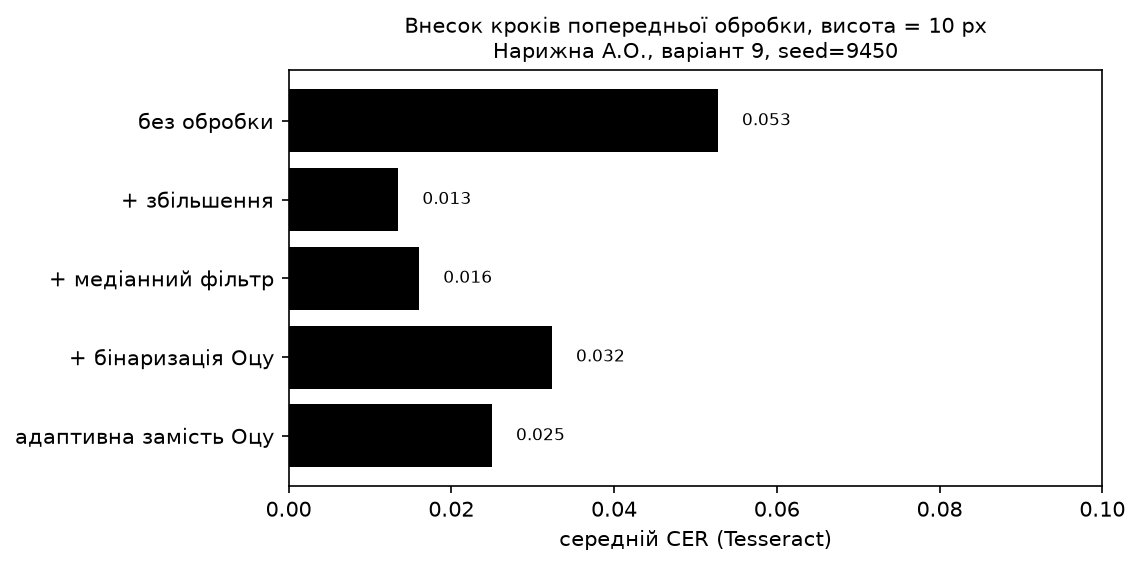

In [1]:
import os, re, time, unicodedata
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import pytesseract
from rapidfuzz.distance import Levenshtein

pytesseract.pytesseract.tesseract_cmd = r"D:\Tesseract-OCR\tesseract.exe"

def preprocess(img, steps=()):
    out = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if "upscale" in steps:
        out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    if "denoise" in steps:
        out = cv2.medianBlur(out, 3)
    if "binarize" in steps:
        out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    if "adaptive" in steps:
        out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 15)
    return out

# Нормалізація, CER та OCR — з підрозділів 4.4–4.5 методички.
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def ocr_tesseract(img, lang="ukr", psm=7):
    t0 = time.perf_counter()
    d = pytesseract.image_to_data(img, lang=lang, config=f"--oem 1 --psm {psm}",
                                  output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(d["text"], d["conf"])
             if w.strip() and float(c) >= 0]
    text = " ".join(w for w, _ in words)
    conf = np.mean([c for _, c in words]) / 100 if words else 0.0
    return text, conf, time.perf_counter() - t0

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

LVL = 10
ablation = {"без обробки": (), "+ збільшення": ("upscale",),
            "+ медіанний фільтр": ("upscale", "denoise"),
            "+ бінаризація Оцу": ("upscale", "denoise", "binarize"),
            "адаптивна замість Оцу": ("upscale", "denoise", "adaptive")}
ds = pd.read_csv("data/ground_truth.csv")
abl_rows = []
for r in ds[ds.level == LVL].itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(r.path)
    for name, steps in ablation.items():
        text, conf, sec = ocr_tesseract(preprocess(img, steps))
        abl_rows.append({"id": r.id, "level": LVL, "step": name,
                         "gt": r.gt, "pred": text, "conf": conf,
                         "sec": sec, "cer": cer(r.gt, text)})
abl_results = pd.DataFrame(abl_rows)
abl_results.to_csv("ablation_results.csv", index=False)
abl = abl_results.groupby("step", sort=False)["cer"].mean()
abl.to_csv("ablation_summary.csv", header=["CER_mean"])
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(abl.index[::-1], abl.values[::-1], color="black")
for y, v in enumerate(abl.values[::-1]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0, max(0.1, abl.max() * 1.2))
ax.set_xlabel("середній CER (Tesseract)")
stamp(ax, f"Внесок кроків попередньої обробки, висота = {LVL} px")
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
print(abl.round(3))
plt.show()


## Пункт 10. Розпізнавання трьох груп даних
Обидва інструменти завершили по 384 зразки: 280 синтетичних, 100 IAM та чотири власні фото. Лише raw. Блоки Tesseract та Ollama незалежні. VLM для неперсональних даних запускалася у Colab з T4; власні фото — локально на CPU з num_ctx=8192. Три ранні синтетичні відповіді VLM збережено з локального тесту.
Не виконуйте всі комірки пункту 10 автоматично: блок Colab запускається тільки у Colab, решта — локально. Готові відповіді пропускаються.


### 10.1 Tesseract локально
Дві комірки нижче: синтетичні дані та IAM, потім чотири власні фото. Шлях до tesseract.exe відповідає цьому ПК.


In [ ]:
%pip install pandas Pillow pytesseract pillow-heif


In [ ]:
import time
from pathlib import Path
import pandas as pd
import pytesseract
from PIL import Image

pytesseract.pytesseract.tesseract_cmd = r"D:\Tesseract-OCR\tesseract.exe"
RESULTS = Path("recognition_results.csv")
KEY = ["group", "id", "level", "engine", "prep"]
synthetic = pd.read_csv("data/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
synthetic["group"], synthetic["lang"] = "synthetic", "ukr"
iam = pd.read_csv("data/iam/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
iam["group"], iam["lang"], iam["level"] = "iam", "eng", -1
columns = ["group", "id", "level", "path", "gt", "lang"]
data = pd.concat([synthetic[columns], iam[columns]], ignore_index=True)
rows = (pd.read_csv(RESULTS, dtype={"id": str}, keep_default_na=False).to_dict("records")
        if RESULTS.exists() else [])
completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
             if r["engine"] == "Tesseract" and r["prep"] == "raw"}

# За прикладом підрозділу 4.4; для рядків --psm 7.
for r in data.itertuples(index=False):
    key = (r.group, str(r.id), int(r.level))
    if key in completed:
        continue
    with Image.open(r.path) as source:
        image = source.convert("L")
    t0 = time.perf_counter()
    output = pytesseract.image_to_data(image, lang=r.lang,
              config="--oem 1 --psm 7", output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(output["text"], output["conf"])
             if w.strip() and float(c) >= 0]
    pred = " ".join(w for w, _ in words)
    conf = sum(c for _, c in words) / len(words) / 100 if words else 0.0
    rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                 "engine": "Tesseract", "model": "Tesseract", "prep": "raw",
                 "gt": r.gt, "pred": pred, "conf": conf,
                 "sec": time.perf_counter() - t0, "lang": r.lang, "psm": 7})
    temporary = RESULTS.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(temporary, index=False)
    temporary.replace(RESULTS)
    completed.add(key)
print("Tesseract: синтетичні дані та IAM завершено")


In [1]:
import time
from pathlib import Path

import pandas as pd
import pytesseract
import pillow_heif
from PIL import Image, ImageOps

pillow_heif.register_heif_opener()

pytesseract.pytesseract.tesseract_cmd = (
    r"D:\Tesseract-OCR\tesseract.exe"
)

RESULTS = Path("recognition_results.csv")
KEY = ["group", "id", "level", "engine", "prep"]

# Зберігаємо всі наявні відповіді.
results = pd.read_csv(
    RESULTS,
    dtype={"id": str},
    keep_default_na=False,
)
rows = results.to_dict("records")

completed = {
    str(row["id"])
    for row in rows
    if row["engine"] == "Tesseract"
    and row["group"] == "own"
    and row["prep"] == "raw"
}

photos = sorted(
    p for p in Path("my_photos").iterdir()
    if p.suffix.lower() == ".heic"
)
assert len(photos) == 4, "Очікуються чотири власні HEIC-фото."

for photo in photos:
    if photo.stem in completed:
        continue

    gt = photo.with_suffix(".txt").read_text(
        encoding="utf-8-sig"
    ).strip()

    lang = "eng" if photo.stem == "IMG_1405" else "ukr"

    with Image.open(photo) as source:
        image = ImageOps.exif_transpose(source).convert("L")

    print(photo.name, "— розпізнавання…", flush=True)
    started = time.perf_counter()

    # За прикладом методички; psm 6 — блок тексту на сторінці.
    output = pytesseract.image_to_data(
        image,
        lang=lang,
        config="--oem 1 --psm 6",
        output_type=pytesseract.Output.DICT,
    )

    words = [
        (word, float(conf))
        for word, conf in zip(output["text"], output["conf"])
        if word.strip() and float(conf) >= 0
    ]

    pred = " ".join(word for word, _ in words)
    confidence = (
        sum(conf for _, conf in words) / len(words) / 100
        if words else 0.0
    )
    seconds = time.perf_counter() - started

    rows.append({
        "group": "own",
        "id": photo.stem,
        "level": -1,
        "engine": "Tesseract",
        "model": "Tesseract",
        "prep": "raw",
        "gt": gt,
        "pred": pred,
        "conf": confidence,
        "sec": seconds,
        "lang": lang,
        "psm": 6,
    })

    temporary = RESULTS.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(temporary, index=False)
    temporary.replace(RESULTS)

    completed.add(photo.stem)
    print(f"Збережено, {seconds:.1f} с", flush=True)

res = pd.DataFrame(rows)

assert not res.duplicated(KEY).any()

print("\nКількість відповідей:")
print(res.groupby(["engine", "group"]).size())

IMG_1402.heic — розпізнавання…
Збережено, 2.3 с
IMG_1403.heic — розпізнавання…
Збережено, 1.4 с
IMG_1404.heic — розпізнавання…
Збережено, 2.5 с
IMG_1405.heic — розпізнавання…
Збережено, 2.5 с

Кількість відповідей:
engine     group    
Tesseract  iam          100
           own            4
           synthetic    280
VLM        iam          100
           own            4
           synthetic    280
dtype: int64


### Пункт 10 — VLM у Colab
Цей блок запускається лише у Colab після встановлення Ollama, завантаження qwen2.5vl:3b та розпакування lab3_colab_data.zip у /content. Потрібні пакети ollama і pandas. Власні фото не завантажуються. Готовий recognition_results.csv завантажте та перенесіть у локальний проєкт під назвою recognition_results_colab.csv, не замінюючи локальний файл.


In [ ]:
%pip install ollama pandas


In [ ]:
import os
os.chdir("/content")
from pathlib import Path
import time
import ollama
import pandas as pd

MODEL = "qwen2.5vl:3b"
RESULTS = Path("recognition_results.csv")
PROMPT = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. "
          "Нічого не виправляй, не перекладай і не додавай пояснень.")
KEY = ["group", "id", "level", "engine", "model", "prep"]

def read_results(path):
    if path.exists():
        return pd.read_csv(path, dtype={"id": str}, keep_default_na=False).to_dict("records")
    return []

def recognize_vlm(data, rows):
    completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
                 if r["engine"] == "VLM" and r["model"] == MODEL and r["prep"] == "raw"}
    for r in data.itertuples(index=False):
        key = (r.group, str(r.id), int(r.level))
        if key in completed:
            continue
        if not Path(r.path).is_file():
            raise FileNotFoundError(r.path)
        print(r.group, r.id, r.level, "— розпізнавання…", flush=True)
        t0 = time.perf_counter()
        response = ollama.chat(model=MODEL, options=OPTIONS,
                              messages=[{"role": "user", "content": PROMPT,
                                         "images": [str(r.path)]}])
        seconds = time.perf_counter() - t0
        rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                     "engine": "VLM", "model": MODEL, "prep": "raw", "gt": r.gt,
                     "pred": response["message"]["content"], "conf": None, "sec": seconds,
                     "lang": r.lang, "psm": r.psm})
        temporary = RESULTS.with_suffix(".tmp.csv")
        pd.DataFrame(rows).to_csv(temporary, index=False)
        temporary.replace(RESULTS)
        completed.add(key)
        print(f"Збережено, {seconds:.1f} с", flush=True)
    return pd.DataFrame(rows)

# У Colab GPU не вимикаємо.
OPTIONS = {"temperature": 0}
synthetic = pd.read_csv("data/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
synthetic["group"], synthetic["lang"], synthetic["psm"] = "synthetic", "ukr", 7
iam = pd.read_csv("data/iam/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
iam["group"], iam["lang"], iam["psm"], iam["level"] = "iam", "eng", 7, -1
columns = ["group", "id", "level", "path", "gt", "lang", "psm"]
data = pd.concat([synthetic[columns], iam[columns]], ignore_index=True)
assert data.groupby("group").size().to_dict() == {"synthetic": 280, "iam": 100}
results = recognize_vlm(data, read_results(RESULTS))
vlm = results[(results.engine == "VLM") & (results.model == MODEL)
              & (results.prep == "raw") & results.group.isin(["synthetic", "iam"])]
assert vlm.groupby("group").size().to_dict() == {"synthetic": 280, "iam": 100}
assert not vlm.duplicated(["group", "id", "level"]).any()
print("Colab завершено: 380 відповідей VLM")
from google.colab import files
files.download(str(RESULTS))


### Пункт 10 — VLM для власних фото локально
Цей блок запускається на ПК з папки проєкту. Потрібна відкрита Ollama з моделлю qwen2.5vl:3b. Встановлення: %pip install ollama pandas Pillow pillow-heif. Блок спочатку імпортує відповіді VLM із recognition_results_colab.csv, якщо він є, та зберігає локальні відповіді Tesseract. Потім розпізнає лише чотири власні фото. num_gpu=0 обходить виявлений збій CUDA на робочому ПК. Власні фото не надсилаються в Colab.


In [ ]:
%pip install ollama pandas Pillow pillow-heif


In [2]:
from pathlib import Path
import time
import ollama
import pandas as pd

MODEL = "qwen2.5vl:3b"
RESULTS = Path("recognition_results.csv")
PROMPT = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. "
          "Нічого не виправляй, не перекладай і не додавай пояснень.")
KEY = ["group", "id", "level", "engine", "model", "prep"]

def read_results(path):
    if path.exists():
        return pd.read_csv(path, dtype={"id": str}, keep_default_na=False).to_dict("records")
    return []

def recognize_vlm(data, rows):
    completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
                 if r["engine"] == "VLM" and r["model"] == MODEL and r["prep"] == "raw"}
    for r in data.itertuples(index=False):
        key = (r.group, str(r.id), int(r.level))
        if key in completed:
            continue
        if not Path(r.path).is_file():
            raise FileNotFoundError(r.path)
        print(r.group, r.id, r.level, "— розпізнавання…", flush=True)
        t0 = time.perf_counter()
        response = ollama.chat(model=MODEL, options=OPTIONS,
                              messages=[{"role": "user", "content": PROMPT,
                                         "images": [str(r.path)]}])
        seconds = time.perf_counter() - t0
        rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                     "engine": "VLM", "model": MODEL, "prep": "raw", "gt": r.gt,
                     "pred": response["message"]["content"], "conf": None, "sec": seconds,
                     "lang": r.lang, "psm": r.psm})
        temporary = RESULTS.with_suffix(".tmp.csv")
        pd.DataFrame(rows).to_csv(temporary, index=False)
        temporary.replace(RESULTS)
        completed.add(key)
        print(f"Збережено, {seconds:.1f} с", flush=True)
    return pd.DataFrame(rows)

from PIL import Image, ImageOps
import pillow_heif
pillow_heif.register_heif_opener()
# На ПК зі збоєм CUDA вимикаємо GPU лише для цього виклику.
OPTIONS = {
    "temperature": 0,
    "num_gpu": 0,
    "num_ctx": 8192,
}

# CSV із Colab покладіть поруч із ноутбуком під цією окремою назвою.
# Наявний локальний recognition_results.csv з відповідями Tesseract не замінюйте.
rows = read_results(RESULTS)
cloud = Path("recognition_results_colab.csv")
if cloud.exists():
    imported = [r for r in read_results(cloud) if r["engine"] == "VLM"
                and r["model"] == MODEL and r["prep"] == "raw"
                and r["group"] in ["synthetic", "iam"]]
    merged = pd.DataFrame(rows + imported).drop_duplicates(KEY, keep="last")
    rows = merged.to_dict("records")
    temporary = RESULTS.with_suffix(".tmp.csv")
    merged.to_csv(temporary, index=False)
    temporary.replace(RESULTS)

Path("data/my_photos").mkdir(parents=True, exist_ok=True)
own_rows = []
for photo in sorted(Path("my_photos").iterdir()):
    if photo.suffix.lower() != ".heic":
        continue
    gt = photo.with_suffix(".txt").read_text(encoding="utf-8-sig").strip()
    png = Path("data/my_photos") / (photo.stem + ".png")
    with Image.open(photo) as image:
        ImageOps.exif_transpose(image).convert("RGB").save(png)
    own_rows.append({"group": "own", "id": photo.stem, "level": -1,
                     "path": png.as_posix(), "gt": gt,
                     "lang": "eng" if photo.stem == "IMG_1405" else "ukr", "psm": 6})
data = pd.DataFrame(own_rows)
assert len(data) == 4, "Очікуються чотири HEIC-фото з однойменними TXT"
results = recognize_vlm(data, rows)
vlm = results[(results.engine == "VLM") & (results.model == MODEL)
              & (results.prep == "raw") & (results.group == "own")]
assert len(vlm) == 4
assert not vlm.duplicated(["group", "id", "level"]).any()
print("Власні фото завершено: 4 відповіді VLM")


own IMG_1404 -1 — розпізнавання…
Збережено, 433.6 с
own IMG_1405 -1 — розпізнавання…
Збережено, 390.8 с
Власні фото завершено: 4 відповіді VLM


### Перевірка пункту 10
Запускати локально після завершення Colab, імпорту CSV та розпізнавання власних фото.


In [1]:
import pandas as pd
res = pd.read_csv("recognition_results.csv", dtype={"id": str}, keep_default_na=False)
print(res.groupby(["engine", "group"]).size())
expected = {("Tesseract", "synthetic"): 280, ("Tesseract", "iam"): 100, ("Tesseract", "own"): 4, ("VLM", "synthetic"): 280, ("VLM", "iam"): 100, ("VLM", "own"): 4}
assert res.groupby(["engine", "group"]).size().to_dict() == expected
assert not res.duplicated(["group", "id", "level", "engine", "prep"]).any()
assert set(res["prep"]) == {"raw"}
assert set(res.loc[res.engine == "VLM", "model"]) == {"qwen2.5vl:3b"}


engine     group    
Tesseract  iam          100
           own            4
           synthetic    280
VLM        iam          100
           own            4
           synthetic    280
Перевірку пройдено: 768 відповідей.
